# 05 · Model training and comparison

This notebook **re-runs the complete default experiment from scratch** and checks the result against the artefacts
committed in `experiments/default`, which the Streamlit app reads.

| Item | Setting |
|---|---|
| Algorithms | Dummy, logistic regression, decision tree, random forest, SVM, XGBoost, LightGBM |
| Strategies | none, class weights, SMOTENC, random oversampling |
| Configurations | 25 (the dummy runs once) |
| Search | `RandomizedSearchCV`, 30 candidates, 5-fold stratified CV on the training split, scoring PR-AUC |
| Comparison | tuned configurations re-scored with 3 × 5-fold repeated stratified CV (a different seed) |
| Selection | one-standard-error rule on mean CV PR-AUC |
| Threshold | maximise F1 on out-of-fold training predictions |

Runtime is about 10 minutes on a laptop.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from talentscope import config
from talentscope.reporting import figures as F
F.setup()
print("TalentScope root:", ROOT.name, "| seed", config.RANDOM_SEED)

TalentScope root: TalentScope | seed 42


In [2]:
import time
from talentscope.modeling import ExperimentConfig, run_experiment, load_bundle, MODEL_SPECS
cfg = ExperimentConfig(name="default")
t0 = time.time()
result = run_experiment(cfg)
print(f"finished in {time.time() - t0:.0f} s")

finished in 616 s


## 1. Reproducibility check against the committed artefacts

In [3]:
saved = load_bundle()
a = result.cv_summary.set_index("combo").sort_index()
s = saved.cv_summary.set_index("combo").sort_index()
cols = ["cv_pr_auc_mean", "cv_pr_auc_std", "cv_roc_auc_mean", "cv_brier_mean", "oof_threshold"]
diff = (a[cols] - s[cols]).abs().max()
print("largest absolute difference per column:\n", diff.round(8))
print("selected now:", result.selection["combo"], "| committed:", saved.selection["combo"])
print("held-out PR-AUC now / committed:", round(result.test_metrics["pr_auc"], 6), "/", round(saved.test_metrics["pr_auc"], 6))
assert diff.max() < 1e-6 and result.selection["combo"] == saved.selection["combo"]

largest absolute difference per column:
 cv_pr_auc_mean     4.800e-07
cv_pr_auc_std      4.800e-07
cv_roc_auc_mean    4.000e-07
cv_brier_mean      4.800e-07
oof_threshold      0.000e+00
dtype: float64
selected now: logreg|none | committed: logreg|none
held-out PR-AUC now / committed: 0.59791 / 0.59791


The fresh run matches the committed artefacts to rounding precision: same scores, same selected model, same threshold
and same test result. Every number in the app can therefore be regenerated with `python scripts/train_default.py`.

## 2. Cross-validated comparison

In [4]:
table = result.cv_summary[["model_name", "strategy_name", "cv_pr_auc_mean", "cv_pr_auc_std", "cv_roc_auc_mean",
                           "cv_brier_mean", "oof_f1", "oof_threshold", "fit_seconds", "selected"]]
table.style.format({c: "{:.3f}" for c in ["cv_pr_auc_mean", "cv_pr_auc_std", "cv_roc_auc_mean", "cv_brier_mean", "oof_f1"]})

,model_name,strategy_name,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_brier_mean,oof_f1,oof_threshold,fit_seconds,selected
0,Logistic regression,No rebalancing,0.662,0.060,0.840,0.091,0.608,0.360000,32.200000,True
1,Support vector machine,No rebalancing,0.657,0.071,0.839,0.089,0.621,0.330000,13.300000,False
2,Support vector machine,Class weights,0.651,0.069,0.837,0.092,0.615,0.340000,20.700000,False
3,XGBoost,No rebalancing,0.640,0.066,0.825,0.093,0.601,0.370000,14.600000,False
4,Support vector machine,Random oversampling,0.637,0.069,0.835,0.147,0.601,0.700000,49.700000,False
5,Logistic regression,Class weights,0.635,0.064,0.832,0.156,0.582,0.650000,5.300000,False
6,XGBoost,Class weights,0.632,0.061,0.824,0.127,0.599,0.580000,13.300000,False
7,Logistic regression,Random oversampling,0.625,0.068,0.829,0.159,0.577,0.630000,6.300000,False
8,LightGBM,No rebalancing,0.624,0.068,0.821,0.095,0.589,0.280000,15.500000,False
9,LightGBM,Class weights,0.619,0.070,0.814,0.136,0.596,0.570000,13.600000,False


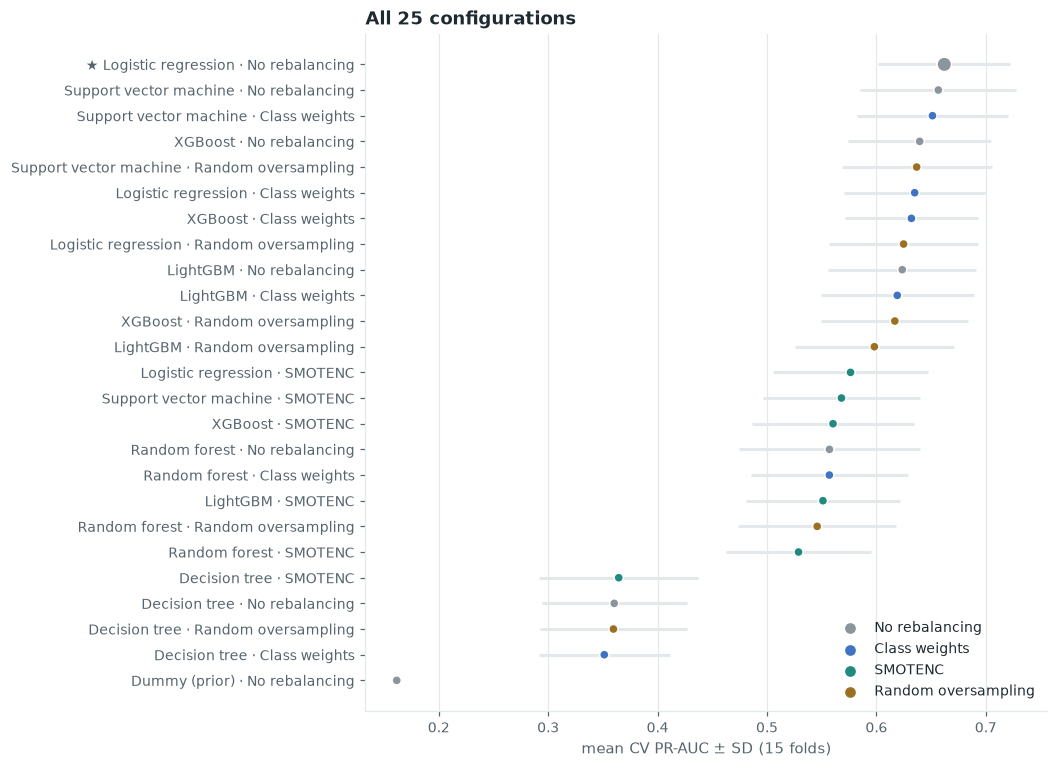

In [5]:
r = result.cv_summary.sort_values("cv_pr_auc_mean")
fig, ax = plt.subplots(figsize=(8, 8))
yy = np.arange(len(r))
ax.errorbar(r["cv_pr_auc_mean"], yy, xerr=r["cv_pr_auc_std"], fmt="none", ecolor=F.GRID, elinewidth=2)
ax.scatter(r["cv_pr_auc_mean"], yy, c=[F.STRATEGY_COLORS[s] for s in r["strategy"]], s=[90 if s else 36 for s in r["selected"]],
           marker="o", zorder=3, edgecolor="white")
ax.set_yticks(yy, [("★ " if s else "") + f"{m} · {t}" for m, t, s in zip(r["model_name"], r["strategy_name"], r["selected"])])
for key, label in [("none", "No rebalancing"), ("class_weight", "Class weights"), ("smotenc", "SMOTENC"), ("random_oversample", "Random oversampling")]:
    ax.scatter([], [], color=F.STRATEGY_COLORS[key], label=label)
ax.legend(loc="lower right"); ax.set_xlabel("mean CV PR-AUC ± SD (15 folds)"); ax.grid(axis="y", visible=False)
ax.set_title("All 25 configurations"); plt.show()

**Reading the ranking**

* **Every model clearly beats the dummy baseline** (PR-AUC about 0.16, the prevalence).
* **The simplest model wins.** Unregularised-looking but L2-penalised logistic regression without rebalancing has the
  highest mean PR-AUC. SVM and XGBoost follow within a fraction of a standard deviation.
* **Random forest and the single decision tree trail.** The tree in particular overfits small leaf sets; even tuned, it
  sits near 0.36.
* **Fold-to-fold SD (about 0.06) is large next to the gaps between the top configurations** (about 0.005 to 0.02).
  Many of these differences are not real.

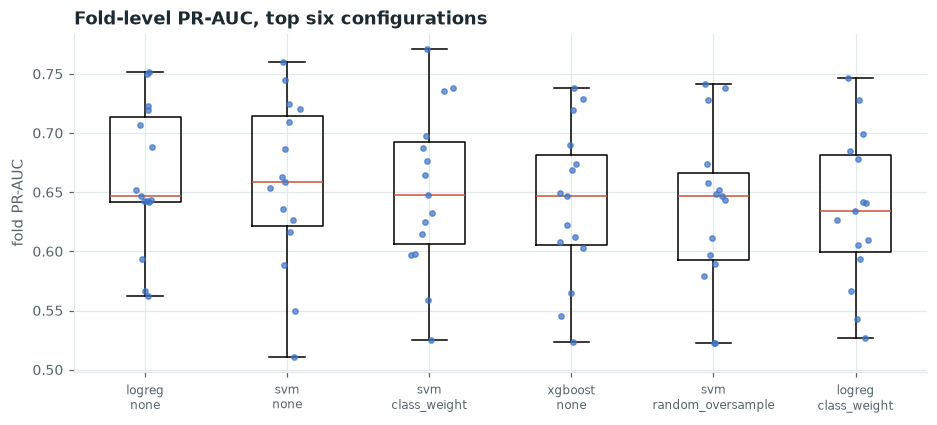

In [6]:
folds = result.cv_folds
top = result.cv_summary.head(6)["combo"].tolist()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([folds[folds.combo == c]["pr_auc"] for c in top], widths=0.5, medianprops=dict(color=F.CLAY))
for i, c in enumerate(top, 1):
    v = folds[folds.combo == c]["pr_auc"]
    ax.scatter(np.random.default_rng(i).normal(i, 0.05, len(v)), v, s=12, color=F.BLUE, alpha=0.7, zorder=3)
ax.set_xticks(range(1, len(top) + 1), [c.replace("|", "\n") for c in top], fontsize=8)
ax.set_ylabel("fold PR-AUC"); ax.set_title("Fold-level PR-AUC, top six configurations"); plt.show()

## 3. Is the winner really better? Paired fold differences

In [7]:
from scipy import stats
sel = result.selection["combo"]
piv = folds.pivot(index="fold", columns="combo", values="pr_auc")
rows = []
for c in top[1:]:
    d = piv[sel] - piv[c]
    t = stats.ttest_1samp(d, 0)
    rows.append({"versus": c, "mean diff": d.mean(), "SD diff": d.std(ddof=1), "folds selected wins": int((d > 0).sum()),
                 "paired t p-value": t.pvalue})
pd.DataFrame(rows)

,versus,mean diff,SD diff,folds selected wins,paired t p-value
0,svm|none,0.005,0.025,8,4.147e-01
1,svm|class_weight,0.011,0.025,9,1.136e-01
2,xgboost|none,0.023,0.043,10,6.015e-02
3,svm|random_oversample,0.025,0.027,12,2.602e-03
4,logreg|class_weight,0.027,0.015,15,5.263e-06


Folds share training rows, so a paired t-test on CV folds is optimistic. Even so, the selected model's advantage over
the runners-up is small and inconsistent from fold to fold. This is the case the **one-standard-error rule** is for:
among configurations within one standard error of the best, take the simplest. Here the best and the simplest coincide,
so the rule confirms logistic regression rather than overriding it.

## 4. The search itself

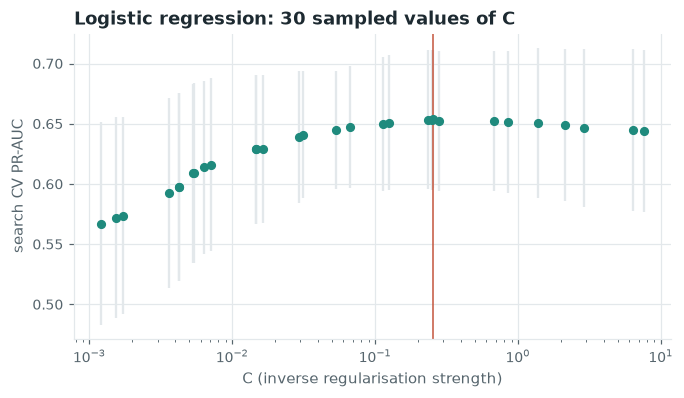

,tuned parameters
dummy|none,{}
logreg|none,{'C': 0.2538}
logreg|class_weight,{'C': 0.114}
logreg|smotenc,{'C': 0.0036}
logreg|random_oversample,{'C': 0.0315}
tree|none,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
tree|class_weight,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
tree|smotenc,"{'criterion': 'entropy', 'max_depth': 7, 'min_..."
tree|random_oversample,"{'criterion': 'gini', 'max_depth': 7, 'min_sam..."
forest|none,"{'max_depth': 6, 'max_features': 'sqrt', 'min_..."


In [8]:
tr = result.search_trials[result.search_trials.combo == "logreg|none"].copy()
tr["C"] = tr["params"].map(lambda s: __import__("json").loads(s)["C"])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(tr["C"], tr["mean_cv_pr_auc"], yerr=tr["std_cv_pr_auc"], fmt="o", color=F.TEAL, ecolor=F.GRID, ms=5)
ax.set_xscale("log"); ax.set_xlabel("C (inverse regularisation strength)"); ax.set_ylabel("search CV PR-AUC")
ax.axvline(result.selection["params"]["C"], color=F.CLAY, lw=1)
ax.set_title("Logistic regression: 30 sampled values of C"); plt.show()
pd.Series(result.best_params).map(lambda p: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items()}).to_frame("tuned parameters")

The PR-AUC curve over *C* is flat across more than an order of magnitude. The model is not sensitive to the exact
regularisation strength, which is reassuring for its stability.

## 5. Unsuccessful experiments, kept on the record

* **SMOTENC** reduced PR-AUC for five of six algorithms and gave no meaningful gain for the sixth (notebook 04).
* **Random forest** underperformed gradient boosting and logistic regression despite tuning depth, leaf size and
  feature sampling.
* **A single decision tree** is far behind (about 0.36). It is kept as an interpretable reference, not a candidate.
* **More complex models did not help.** XGBoost, LightGBM and the SVM all landed within noise of logistic regression or
  below it.

## Summary

The selected configuration is **logistic regression with no rebalancing**, with *C* tuned by randomised search and a
threshold to be chosen on out-of-fold predictions. Its held-out evaluation is the subject of notebook 06.

In [9]:
pd.Series({k: v for k, v in result.selection.items() if k not in ("reason",)}).to_frame("selection")

,selection
combo,logreg|none
model,logreg
model_name,Logistic regression
strategy,none
strategy_name,No rebalancing
rule,one_se
best_combo_by_mean,logreg|none
one_se_floor,0.646
cv_pr_auc_mean,0.662
cv_pr_auc_std,0.06
